# Helsinki region: the nearer places people pass over, by postal code

How many closer POIs of the same type does a resident skip on a typical visit, and
how does that depend on how many POIs there are around home?

The decent-week notebooks (`02.5`, `02.6`) read trip costs off each resident's own
visits, which needs the mobile-phone stays. The amenity notebooks (`02.3`, `02.4`)
need only OpenStreetMap, GTFS and population, but their typical trip is a fixed
access level. This notebook measures, from the Helsinki stays, where between
"the nearest" and "anywhere" people actually go, as a rank: the number of POIs of
the same category that lie nearer to home than the one visited. A rank is a
quantity another city can use without stays: the typical trip for a category
becomes the trip to the (rank + 1)-th nearest POI of that category, which the
hexagon-to-amenity matrices of `02.3` give for any mode.

**Logic, in one paragraph.** For every user, the stays outside home and work are
matched with the POIs of each category in the stay hexagon, as in `02.5`. For one
stay and category, the rank is the number of POIs of that category in hexagons
strictly nearer to the home hexagon than the stay hexagon, by walking distance along
the street network between hexagon centres (straight-line distance is kept beside it
as a check). Each stay enters a user's distribution with weight
`visits x POI count`; sorting the stays by rank gives the cumulative share of the
user's visits made within a given rank, and the rank at 50 % is the user's typical
rank for the category (20 % is the near rank, the counterpart of the threshold in
`02.6`). Exposure is the paper's: the POIs of the category inside the hexagon of the stay,
the ones the visit exposed the user to.
Per postal code the per-user values are summarised across residents, and the
rank is then related to exposure.

**Inputs** (all pre-existing)

- `users_and_stays_3months.parquet`: user x stay hexagon, visits, home hexagon.
- `pois_per_hex_new_class.parquet`: POIs per H3-9 hexagon and category of the
  carbon-budget paper.
- `Postinumeroalueet_2024.shp`: postal codes of Helsinki, Espoo and Vantaa.
- `networks/helsinki-streets.cafein`: the street network of `02.1`, for the walking distances.

**Outputs** on scratch under `carbon-advantage/helsinki/visited-rank/`

- `walk-distance/`: streamed cafein matrix, home hexagon x POI hexagon, walking mode.

- `rank_by_user.parquet`: user x category: rank at the thresholds, share of visits
  to a nearest POI, distance of the typical visit and of the nearest POI, exposure of
  the typical visit and POIs exposed to in total.
- `rank_by_postal_code.parquet`, `rank_by_postal_code.csv`: the same summarised per
  postal code and category.
- `rank_summary.csv`: the city-wide numbers per category, the ones to carry over.
- `parameters.json`: the settings below.

In [1]:
import json
import time
from pathlib import Path

import geopandas as gpd
import h3
import matplotlib.patheffects as patheffects
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import numpy as np
import pandas as pd
from pyproj import Transformer
from cafein import StreetNetwork, TravelCostMatrix
from cafein._streaming import read_shards
from shapely.geometry import Polygon

## Parameters

The stays are filtered as in `02.5` (home known, home and work hexagons removed,
at least `MIN_VISITS_PER_USER` visits to hexagons with POIs of the category). The
rank counts POIs in hexagons strictly nearer than the visited hexagon, so a visit to
one of the nearest POIs has rank 0, and POIs in the home hexagon itself always count
as nearer. Distances are walking distances along the street network between hexagon
centres (`DISTANCE_BASIS = "network"`), mode-neutral and the same recipe for every
city with a street artifact; straight-line distances in EPSG:3067 are computed as
well and compared. Exposure follows the carbon-budget paper: the POIs of the category in the hexagon of
the stay, nothing around the home.

In [2]:
PAPER = Path("/projappl/project_2010423/carbon_budgets_paper")
SCRATCH = Path("/scratch/project_2010423")
RESULTS = SCRATCH / "carbon-advantage" / "helsinki" / "visited-rank"
RESULTS.mkdir(parents=True, exist_ok=True)

STAYS = SCRATCH / "data" / "users_and_stays_3months.parquet"
POIS = PAPER / "data" / "pois_per_hex_new_class.parquet"
POSTAL_CODES = PAPER / "data" / "postal_code" / "Postinumeroalueet_2024.shp"
METRIC_CRS = "EPSG:3067"
STREET_ARTIFACT = Path("../networks/helsinki-streets.cafein")   # 02.1
WALK_MATRIX = RESULTS / "walk-distance"

# Destination categories of the carbon-budget paper ("Others / Not sure" left out).
CATEGORIES = [
    "Education",
    "Healthcare and Health",
    "Recreational, Outdoors",
    "Shopping, Errands",
    "Social, Cultural",
]
SHORT = {"Education": "education", "Healthcare and Health": "healthcare",
         "Recreational, Outdoors": "recreation", "Shopping, Errands": "shopping", "Social, Cultural": "social"}

# Cumulative share of a user's visits (percent) at which the rank is read off.
THRESHOLDS = [20, 50]
MAIN_THRESHOLD = 50

# Which distance orders the POIs: "network" (walking distance along the streets) or
# "straight" (straight line between hexagon centres). Both are computed; this one is
# used for the rank, the exposure and the nearest POI.
DISTANCE_BASIS = "network"
MAX_WALK_TIME_MIN = 720   # search limit of the walking matrix, about 60 km; the region is narrower

# Floor for the distance to the nearest POI when it lies in the home hexagon itself:
# the circumradius of an H3-9 hexagon (about 174 m), rounded.
HEXAGON_RADIUS_M = 200

WEIGHT_BY_FREQUENCY = True      # each stay weighted by its visits (and the POI count)
MIN_VISITS_PER_USER = 5         # visits to hexagons with POIs of the category, as in 02.5
MIN_USERS_PER_POSTAL_CODE = 20  # residents a postal code needs to be reported
KUNTA_COLOURS = {"Helsinki": "#0072B2", "Espoo": "#E69F00", "Vantaa": "#009E73"}
# 02380 Suvisaaristo (Espoo) is a 175 km2 polygon of mostly open sea; it is left off the maps.
SEA_POSTAL_CODES = ["02380"]
# Sea polygons (OSM coastline, osmdata.openstreetmap.de simplified water polygons) that cut
# the postal codes to land on the maps, and the places named on every map for orientation.
WATER_POLYGONS = SCRATCH / "carbon-advantage" / "basemap" / "simplified-water-polygons-split-3857" / "simplified_water_polygons.shp"
LANDMARKS = {
    "00100": "Centre", "00520": "Pasila", "00530": "Kallio", "00200": "Lauttasaari", "00700": "Malmi",
    "00930": "Itäkeskus", "00980": "Vuosaari", "02100": "Tapiola", "02600": "Leppävaara", "02230": "Matinkylä",
    "02770": "Espoon keskus", "01300": "Tikkurila", "01600": "Myyrmäki", "01700": "Kivistö",
}

json.dump(
    {
        "categories": CATEGORIES,
        "thresholds_percent": THRESHOLDS,
        "main_threshold_percent": MAIN_THRESHOLD,
        "exposure": "POIs of the category inside the hexagon of the stay, as in the carbon-budget paper",
        "hexagon_radius_m": HEXAGON_RADIUS_M,
        "distance_basis": DISTANCE_BASIS,
        "distances": {"network": "walking distance along the street network between H3-9 hexagon centres (cafein walk mode)",
                      "straight": "straight line between H3-9 hexagon centres, EPSG:3067"},
        "max_walk_time_min": MAX_WALK_TIME_MIN,
        "rank": "POIs of the category in hexagons strictly nearer to home than the visited hexagon",
        "weight_by_frequency": WEIGHT_BY_FREQUENCY,
        "min_visits_per_user": MIN_VISITS_PER_USER,
        "min_users_per_postal_code": MIN_USERS_PER_POSTAL_CODE,
        "stays": str(STAYS),
        "pois": str(POIS),
    },
    open(RESULTS / "parameters.json", "w"),
    indent=2,
)
print(f"results -> {RESULTS}")

results -> /scratch/project_2010423/carbon-advantage/helsinki/visited-rank


## 1. Stays outside home and work, with the postal code of the home

The same rows and the same postal-code rule as `02.5`: one row per user and visited
hexagon with the number of visits over the three months, home and work hexagons
removed, each home hexagon taking the postal code it overlaps most.

In [3]:
stays = pd.read_parquet(STAYS)
stays = stays.loc[stays["home_gid9"].notna() & (stays["is_home"] == 0) & (stays["is_work"] == 0)]
stays = stays[["user_id", "home_gid9", "stay_gid9", "frequency_period"]].rename(columns={"frequency_period": "visits"})
stays = stays.loc[stays["stay_gid9"] != stays["home_gid9"]].reset_index(drop=True)
print(f"{len(stays):,} user-hexagon rows, {stays['user_id'].nunique():,} users, {stays['visits'].sum():,} visits")


def hexagon_polygon(cell):
    """Boundary of an H3 cell as a (lon, lat) polygon, h3 v3 or v4."""
    if hasattr(h3, "h3_to_geo_boundary"):  # h3 v3
        return Polygon(h3.h3_to_geo_boundary(cell, geo_json=True))
    return Polygon((lng, lat) for lat, lng in h3.cell_to_boundary(cell))  # h3 v4


postal = gpd.read_file(POSTAL_CODES)[["Posnro", "Nimi", "Kunta", "geometry"]]
home_cells = stays["home_gid9"].unique()
homes = gpd.GeoDataFrame({"home_gid9": home_cells}, geometry=[hexagon_polygon(c) for c in home_cells], crs="EPSG:4326").to_crs(postal.crs)
pieces = gpd.overlay(homes, postal, how="intersection")
pieces["area"] = pieces.geometry.area
home_postal = pieces.sort_values("area", ascending=False).drop_duplicates("home_gid9")[["home_gid9", "Posnro", "Nimi", "Kunta"]]

stays = stays.merge(home_postal, on="home_gid9", how="inner")
print(f"{len(home_postal):,} home hexagons in {home_postal['Posnro'].nunique()} postal codes; {stays['user_id'].nunique():,} users kept")
stays.drop_duplicates("user_id")["Kunta"].value_counts().rename("users").to_frame()

755,139 user-hexagon rows, 73,659 users, 1,482,853 visits


3,754 home hexagons in 166 postal codes; 73,357 users kept


,users
Kunta,
Helsinki,33713
Espoo,23984
Vantaa,15660


## 2. POIs per hexagon and hexagon centres

All hexagons with POIs of the kept categories, visited or not, since the rank counts
every nearer POI. Centres are projected to metres.

In [4]:
pois = (
    pd.read_parquet(POIS)
    .query("category in @CATEGORIES")
    .pivot_table(index="h3_id", columns="category", values="count", aggfunc="sum", fill_value=0)
    .reindex(columns=CATEGORIES, fill_value=0)
)
pois = pois.loc[pois.sum(axis=1) > 0]


def hexagon_centre(cell):
    """(lat, lon) of an H3 cell centre, h3 v3 or v4."""
    if hasattr(h3, "h3_to_geo"):  # h3 v3
        return h3.h3_to_geo(cell)
    return h3.cell_to_latlng(cell)  # h3 v4


to_metric = Transformer.from_crs("EPSG:4326", METRIC_CRS, always_xy=True)


def centres_xy(cells):
    """n x 2 array of projected centre coordinates (metres) for an iterable of H3 cells."""
    lat, lon = zip(*(hexagon_centre(c) for c in cells))
    x, y = to_metric.transform(lon, lat)
    return np.column_stack([x, y])


poi_cells = pois.index.to_numpy()
poi_xy = centres_xy(poi_cells)
poi_counts = pois.to_numpy(dtype=np.int64)
print(f"{len(pois):,} hexagons with POIs; POIs per category:")
pois.sum().rename("pois").to_frame().T

3,482 hexagons with POIs; POIs per category:


category,Education,Healthcare and Health,"Recreational, Outdoors","Shopping, Errands","Social, Cultural"
pois,1289,1523,3809,6280,7206


## 3. Walking distance from every home hexagon to every POI hexagon

A cafein street matrix in walking mode from the home hexagons to the hexagons with
POIs, streamed to Parquet once and reused on later runs; the network distance of
each pair is the walking distance along the streets. Pairs the router cannot connect
stay missing and are reported: they are never counted as nearer, and a visit to such
a hexagon gets no rank.

In [5]:
def matrix_complete(path):
    """True when a streamed matrix directory has every shard completed."""
    manifest = Path(path) / "manifest.json"
    if not manifest.is_file():
        return False
    shards = json.loads(manifest.read_text())["shards"]
    return bool(shards) and all(shard["completed"] for shard in shards)


def hexagon_layer(cells):
    """H3 cells as a polygon layer in the cafein.zones protocol (id, centre, geometry)."""
    centres = [hexagon_centre(c) for c in cells]
    return gpd.GeoDataFrame(
        {"id": list(cells), "centroid_lat": [c[0] for c in centres], "centroid_lon": [c[1] for c in centres]},
        geometry=[hexagon_polygon(c) for c in cells], crs="EPSG:4326",
    )


if not matrix_complete(WALK_MATRIX):
    streets = StreetNetwork.load(STREET_ARTIFACT)
    started = time.time()
    TravelCostMatrix.to_parquet(
        streets, hexagon_layer(home_cells), hexagon_layer(poi_cells),
        transport_mode="walk", max_street_time=MAX_WALK_TIME_MIN, perspectives="private",
        output_time_units="seconds", output=WALK_MATRIX, resume=WALK_MATRIX.exists(),
    )
    print(f"walking matrix computed in {time.time() - started:.0f} s -> {WALK_MATRIX}")
else:
    print(f"walking matrix complete -> {WALK_MATRIX}")

walk = read_shards(WALK_MATRIX)[["from_id", "to_id", "network_distance_m"]]
home_index, poi_index = pd.Index(home_cells), pd.Index(poi_cells)
walk_distance = np.full((len(home_index), len(poi_index)), np.nan)
walk_distance[home_index.get_indexer(walk["from_id"].astype(str)), poi_index.get_indexer(walk["to_id"].astype(str))] = walk["network_distance_m"].to_numpy(dtype=float)
covered = np.isfinite(walk_distance).mean()
print(f"{len(walk):,} pairs, {covered:.1%} of the {walk_distance.size:,} home x POI hexagon pairs connected; "
      f"walking distance median {np.nanmedian(walk_distance) / 1000:.1f} km, max {np.nanmax(walk_distance) / 1000:.1f} km")
walk.head()

walking matrix complete -> /scratch/project_2010423/carbon-advantage/helsinki/visited-rank/walk-distance


13,096,346 pairs, 98.9% of the 13,238,564 home x POI hexagon pairs connected; walking distance median 14.3 km, max 43.2 km


,from_id,to_id,network_distance_m
0,8908996aa2fffff,8908996102bffff,10082.850000
1,8908996aa2fffff,89089961033ffff,10730.543233
2,8908996aa2fffff,890899610a7ffff,11713.885050
3,8908996aa2fffff,890899610bbffff,11194.115000
4,8908996aa2fffff,890899610c7ffff,10547.145900


## 4. Rank of every visited hexagon, nearest POI of every home

For each home hexagon the POI hexagons are sorted by distance and their POI counts
accumulated per category. A visited hexagon's rank in a category is the accumulated
count just before its own distance, that is the POIs of the category strictly nearer
to home. The first non-zero entry of the accumulation gives the distance to the
nearest POI of the category. Both distance bases are ranked; the rank and the nearest
POI of the main basis go into the analysis, the other basis is kept for the
comparison below. The exposure of a visit is the POI count of the stay hexagon,
merged from the POI table.

In [6]:
stay_cells = stays["stay_gid9"].unique()
xy_of = dict(zip(np.concatenate([poi_cells, home_cells]), np.vstack([poi_xy, centres_xy(home_cells)])))
# Position of each stay hexagon among the POI hexagons; -1 when it holds no POI of the kept categories.
stay_position = poi_index.get_indexer(stays["stay_gid9"])
BASES = ["network", "straight"]
OTHER_BASIS = [b for b in BASES if b != DISTANCE_BASIS][0]

rank_columns = [f"rank_{SHORT[c]}" for c in CATEGORIES]
other_rank_columns = [f"rank_{OTHER_BASIS}_{SHORT[c]}" for c in CATEGORIES]
nearest_columns = [f"nearest_m_{SHORT[c]}" for c in CATEGORIES]

ranks = {basis: np.full((len(stays), len(CATEGORIES)), np.nan) for basis in BASES}
distance_to_stay = {basis: np.full(len(stays), np.nan) for basis in BASES}
home_rows = []
started = time.time()
for home, rows in stays.groupby("home_gid9").indices.items():
    hx = xy_of[home]
    with_poi = rows[stay_position[rows] >= 0]
    positions = stay_position[with_poi]
    d_poi = {"straight": np.hypot(*(poi_xy - hx).T), "network": walk_distance[home_index.get_loc(home)]}
    for basis in BASES:
        d = np.where(np.isfinite(d_poi[basis]), d_poi[basis], np.inf)
        order = np.argsort(d, kind="stable")
        d_sorted = d[order]
        cumulative = np.vstack([np.zeros((1, len(CATEGORIES)), dtype=np.int64), np.cumsum(poi_counts[order], axis=0)])
        d_stay = d[positions]
        reachable = np.isfinite(d_stay)
        ranks[basis][with_poi[reachable]] = cumulative[np.searchsorted(d_sorted, d_stay[reachable], side="left")]
        distance_to_stay[basis][with_poi[reachable]] = d_stay[reachable]
        if basis == DISTANCE_BASIS:
            present = (cumulative[1:] > 0) & np.isfinite(d_sorted)[:, None]
            nearest = np.where(present.any(axis=0), d_sorted[present.argmax(axis=0)], np.nan)
            home_rows.append([home, *nearest])
print(f"{len(home_rows):,} home hexagons in {time.time() - started:.0f} s")

home_table = pd.DataFrame(home_rows, columns=["home_gid9", *nearest_columns])
stays[rank_columns] = ranks[DISTANCE_BASIS]
stays[other_rank_columns] = ranks[OTHER_BASIS]
stays["distance_m"] = distance_to_stay[DISTANCE_BASIS]
stays[f"distance_{OTHER_BASIS}_m"] = distance_to_stay[OTHER_BASIS]
stays = stays.merge(pois, left_on="stay_gid9", right_index=True, how="left")
stays[CATEGORIES] = stays[CATEGORIES].fillna(0).astype(int)
has_poi = stays[CATEGORIES].sum(axis=1) > 0
unranked = has_poi & stays["distance_m"].isna()
print(f"{has_poi.sum():,} stay rows in hexagons with POIs of the kept categories; {unranked.sum():,} of them "
      f"({unranked.mean():.2%}) unreachable by the {DISTANCE_BASIS} distance and left without a rank")
stays.head()

3,754 home hexagons in 2 s


524,398 stay rows in hexagons with POIs of the kept categories; 805 of them (0.11%) unreachable by the network distance and left without a rank


,user_id,home_gid9,stay_gid9,visits,Posnro,Nimi,Kunta,rank_education,rank_healthcare,rank_recreation,...,rank_straight_recreation,rank_straight_shopping,rank_straight_social,distance_m,distance_straight_m,Education,Healthcare and Health,"Recreational, Outdoors","Shopping, Errands","Social, Cultural"
0,00005cb2-f875-42d6-8b4b-e036eaf112b9,8908996aa2fffff,89089968103ffff,1,02710,Viherlaakso,Espoo,31.0,25.0,78.0,...,98.0,89.0,87.0,3161.311824,2556.442872,0,0,0,0,2
1,00005cb2-f875-42d6-8b4b-e036eaf112b9,8908996aa2fffff,89089968c87ffff,1,02710,Viherlaakso,Espoo,5.0,9.0,7.0,...,4.0,0.0,5.0,805.657005,573.822488,0,0,1,0,0
2,00005cb2-f875-42d6-8b4b-e036eaf112b9,8908996aa2fffff,89089968c93ffff,5,02710,Viherlaakso,Espoo,0.0,0.0,2.0,...,2.0,0.0,1.0,391.225884,310.914938,1,2,0,0,1
3,00005cb2-f875-42d6-8b4b-e036eaf112b9,8908996aa2fffff,89089968c9bffff,2,02710,Viherlaakso,Espoo,2.0,3.0,3.0,...,5.0,0.0,5.0,767.531352,621.840532,3,6,4,7,6
4,00005cb2-f875-42d6-8b4b-e036eaf112b9,8908996aa2fffff,8908996d567ffff,3,02710,Viherlaakso,Espoo,396.0,426.0,987.0,...,1021.0,1759.0,1411.0,10566.297020,9124.845675,0,0,3,0,0


Hand check: for one visited hexagon the rank is recomputed by brute force from
the POI table, and the typical home is shown with its exposure.

In [7]:
example = stays.loc[(stays[CATEGORIES].sum(axis=1) > 0) & stays["distance_m"].notna()].iloc[0]
home_position = home_index.get_loc(example["home_gid9"])
d_home = walk_distance[home_position] if DISTANCE_BASIS == "network" else np.hypot(*(poi_xy - xy_of[example["home_gid9"]]).T)
d_example = d_home[poi_index.get_loc(example["stay_gid9"])]
nearer = pois.loc[np.isfinite(d_home) & (d_home < d_example)].sum()
check = pd.DataFrame({"stored rank": example[rank_columns].to_numpy(), "brute force": nearer.to_numpy()}, index=CATEGORIES)
assert (check["stored rank"] == check["brute force"]).all()
print(f"home {example['home_gid9']} -> stay {example['stay_gid9']}, {d_example / 1000:.2f} km by the {DISTANCE_BASIS} distance "
      f"({example[f'distance_{OTHER_BASIS}_m'] / 1000:.2f} km {OTHER_BASIS}), POIs in the stay hexagon: "
      + ", ".join(f"{SHORT[c]} {example[c]}" for c in CATEGORIES if example[c] > 0))
display(check)
print("nearest POI of each category from the same home (metres):")
home_table.loc[home_table["home_gid9"] == example["home_gid9"]].set_index("home_gid9").T

home 8908996aa2fffff -> stay 89089968103ffff, 3.16 km by the network distance (2.56 km straight), POIs in the stay hexagon: social 2


,stored rank,brute force
Education,31.0,31
Healthcare and Health,25.0,25
"Recreational, Outdoors",78.0,78
"Shopping, Errands",71.0,71
"Social, Cultural",79.0,79


nearest POI of each category from the same home (metres):


home_gid9,8908996aa2fffff
nearest_m_education,391.225884
nearest_m_healthcare,391.225884
nearest_m_recreation,0.000000
nearest_m_shopping,767.531352
nearest_m_social,391.225884


The two distance bases compared on the visited hexagons with POIs: the ratio of
walking to straight-line distance, and how far the rank of a visit moves when the
network order replaces the straight-line order.

In [8]:
compared = stays.loc[has_poi & stays["distance_m"].notna() & stays[f"distance_{OTHER_BASIS}_m"].notna()]
network_column = "distance_m" if DISTANCE_BASIS == "network" else "distance_network_m"
straight_column = "distance_m" if DISTANCE_BASIS == "straight" else "distance_straight_m"
ratio = compared[network_column] / compared[straight_column]
print(f"{len(compared):,} visited hexagons with both distances; walking / straight-line distance: "
      f"median {ratio.median():.2f}, p10 {ratio.quantile(0.1):.2f}, p90 {ratio.quantile(0.9):.2f}")
rows = []
for category in CATEGORIES:
    sub = compared.loc[compared[category] > 0]
    a, b = sub[f"rank_{SHORT[category]}"], sub[f"rank_{OTHER_BASIS}_{SHORT[category]}"]
    rows.append({"poi_type": category, "visits": len(sub), f"median rank {DISTANCE_BASIS}": a.median(), f"median rank {OTHER_BASIS}": b.median(),
                 "spearman": a.corr(b, method="spearman"), "median |difference|": (a - b).abs().median(),
                 "share within 10 %": ((a - b).abs() <= 0.1 * np.maximum(a, b).clip(lower=1)).mean()})
pd.DataFrame(rows).set_index("poi_type").round(2)

523,593 visited hexagons with both distances; walking / straight-line distance: median 1.19, p10 1.12, p90 1.37


,visits,median rank network,median rank straight,spearman,median |difference|,share within 10 %
poi_type,,,,,,
Education,232143,172.0,176.0,1.0,7.0,0.72
Healthcare and Health,241615,204.0,208.0,1.0,9.0,0.71
"Recreational, Outdoors",375065,438.0,445.0,1.0,21.0,0.68
"Shopping, Errands",369825,743.0,753.0,1.0,32.0,0.69
"Social, Cultural",392847,720.0,726.0,1.0,36.0,0.67


## 5. Typical rank per user and category

A stay enters the distribution of each category present in its hexagon with weight
`visits x POI count`, the paper's explode by POI; stays without a rank (unreachable)
are left out. Sorting the stays of a user by rank gives the cumulative share of
visits, and the rank at each threshold is the first rank at which the share is
reached. The distance of the same visit is read at the same threshold, and divided
by the distance to the nearest POI of the category from home (floored at
`HEXAGON_RADIUS_M` when that POI is in the home hexagon) gives the detour ratio.
The share of visits with rank 0 is the share made to one of the nearest POIs.
Exposure is read the same way: the POI count of the visited hexagon at each
threshold of the visits, so `exposure_at_50` is the exposure of the typical visit;
`exposed_pois` is the number of POIs of the category in all the hexagons the user
visited, the paper's count of exposed POIs.

In [9]:
def read_at(frame, value, thresholds):
    """Per user: the value at which the cumulative visit share first reaches each threshold."""
    ordered = frame.sort_values(["user_id", value])
    total = ordered.groupby("user_id")["weight"].transform("sum")
    share = ordered.groupby("user_id")["weight"].cumsum() / total
    out = {}
    for threshold in thresholds:
        reached = ordered.loc[share >= threshold / 100]
        out[f"{value}_at_{threshold}"] = reached.groupby("user_id")[value].first()
    return pd.DataFrame(out)


pieces = []
for category in CATEGORIES:
    short = SHORT[category]
    rows = stays.loc[(stays[category] > 0) & stays[f"rank_{short}"].notna(), ["user_id", "home_gid9", "visits", category, f"rank_{short}", "distance_m"]].copy()
    rows["weight"] = rows["visits"] * rows[category] if WEIGHT_BY_FREQUENCY else rows[category]
    rows = rows.rename(columns={f"rank_{short}": "rank"})
    rows["exposure"] = rows[category]
    enough = rows.groupby("user_id")["visits"].sum() >= MIN_VISITS_PER_USER
    rows = rows.loc[rows["user_id"].isin(enough.index[enough])]
    per_user = read_at(rows, "rank", THRESHOLDS).join(read_at(rows, "distance_m", THRESHOLDS)).join(read_at(rows, "exposure", THRESHOLDS))
    per_user["exposed_pois"] = rows.groupby("user_id")[category].sum()
    per_user["share_nearest"] = rows.assign(nearest=(rows["rank"] == 0) * rows["weight"]).groupby("user_id")["nearest"].sum() / rows.groupby("user_id")["weight"].sum()
    per_user["visits"] = rows.groupby("user_id")["visits"].sum()
    per_user["home_gid9"] = rows.groupby("user_id")["home_gid9"].first()
    per_user = per_user.join(home_table.set_index("home_gid9")[[f"nearest_m_{short}"]], on="home_gid9").rename(columns={f"nearest_m_{short}": "nearest_m"})
    pieces.append(per_user.reset_index().assign(poi_type=category))
by_user = pd.concat(pieces, ignore_index=True).merge(home_postal, on="home_gid9", how="left")
by_user[f"detour_ratio_at_{MAIN_THRESHOLD}"] = by_user[f"distance_m_at_{MAIN_THRESHOLD}"] / by_user["nearest_m"].clip(lower=HEXAGON_RADIUS_M)
for t in THRESHOLDS:
    by_user[f"rank_at_{t}_share_of_region"] = by_user[f"rank_at_{t}"] / by_user["poi_type"].map(pois.sum())
by_user.to_parquet(RESULTS / "rank_by_user.parquet", index=False)

print(f"{by_user['user_id'].nunique():,} users with at least {MIN_VISITS_PER_USER} visits in some category; users per category:")
display(by_user.groupby("poi_type")["user_id"].size().rename("users").to_frame().T)
print("Distribution across users of the rank at each threshold, the share of visits to a nearest POI and the detour ratio:")
by_user.groupby("poi_type")[[f"rank_at_{t}" for t in THRESHOLDS] + ["share_nearest", f"detour_ratio_at_{MAIN_THRESHOLD}"]].describe(percentiles=[0.25, 0.5, 0.75]).round(2).T

46,249 users with at least 5 visits in some category; users per category:


poi_type,Education,Healthcare and Health,"Recreational, Outdoors","Shopping, Errands","Social, Cultural"
users,28861,27706,39643,37138,40431


Distribution across users of the rank at each threshold, the share of visits to a nearest POI and the detour ratio:


poi_type                  Education  Healthcare and Health  \
rank_at_20         count   28861.00               27706.00   
                   mean      147.37                 180.06   
                   std       225.89                 267.75   
                   min         0.00                   0.00   
                   25%         7.00                  13.00   
                   50%        37.00                  52.00   
                   75%       187.00                 224.75   
                   max      1278.00                1510.00   
rank_at_50         count   28861.00               27706.00   
                   mean      269.66                 345.09   
                   std       291.65                 352.00   
                   min         0.00                   0.00   
                   25%        25.00                  46.00   
                   50%       142.00                 200.00   
                   75%       471.00                 590.00   
                   max      1278.00                1521.00   
share_nearest      count   28861.00               27706.00   
                   mean        0.03                   0.02   
                   std         0.12                   0.10   
                   min         0.00                   0.00   
                   25%         0.00                   0.00   
                   50%         0.00                   0.00   
                   75%         0.00                   0.00   
                   max         1.00                   1.00   
detour_ratio_at_50 count   28861.00               27706.00   
                   mean       17.67                  16.07   
                   std        18.60                  16.91   
                   min         1.00                   1.00   
                   25%         4.65                   4.68   
                   50%        11.55                  10.57   
                   75%        23.79                  20.92   
                   max       189.69                 152.62   

poi_type                  Recreational, Outdoors  Shopping, Errands  \
rank_at_20         count                39643.00           37138.00   
                   mean                   412.88             695.75   
                   std                    617.05            1033.74   
                   min                      0.00               0.00   
                   25%                     28.00              52.00   
                   50%                    122.00             233.50   
                   75%                    512.00             854.75   
                   max                   3727.00            6229.00   
rank_at_50         count                39643.00           37138.00   
                   mean                   816.04            1325.90   
                   std                    822.93            1374.29   
                   min                      0.00               0.00   
                   25%                    126.00             221.00   
                   50%                    486.00             775.00   
                   75%                   1382.00            2150.75   
                   max                   3762.00            6266.00   
share_nearest      count                39643.00           37138.00   
                   mean                     0.01               0.01   
                   std                      0.06               0.06   
                   min                      0.00               0.00   
                   25%                      0.00               0.00   
                   50%                      0.00               0.00   
                   75%                      0.00               0.00   
                   max                      1.00               1.00   
detour_ratio_at_50 count                39643.00           37138.00   
                   mean                    23.82              22.30   
                   std              

How the rank reads: a user whose typical shopping rank is 12 does half of their
shopping visits at places with at most 12 nearer shops. The table shows the ranks
per category city-wide, as a count and as a share of the region's POIs of the
category; the detour ratio says how many times further than the nearest POI the
typical visit goes; the exposure is the POI count of the hexagon of the typical
visit.

In [10]:
summary_rows = []
for category in CATEGORIES:
    rows = by_user.loc[by_user["poi_type"] == category]
    summary_rows.append({
        "poi_type": category, "users": len(rows), "region_pois": int(pois[category].sum()),
        **{f"rank_at_{t}_median": rows[f"rank_at_{t}"].median() for t in THRESHOLDS},
        **{f"rank_at_{t}_share_of_region": rows[f"rank_at_{t}"].median() / pois[category].sum() for t in THRESHOLDS},
        f"rank_at_{MAIN_THRESHOLD}_p25": rows[f"rank_at_{MAIN_THRESHOLD}"].quantile(0.25),
        f"rank_at_{MAIN_THRESHOLD}_p75": rows[f"rank_at_{MAIN_THRESHOLD}"].quantile(0.75),
        "share_nearest_mean": rows["share_nearest"].mean(),
        f"distance_km_at_{MAIN_THRESHOLD}_median": rows[f"distance_m_at_{MAIN_THRESHOLD}"].median() / 1000,
        "nearest_km_median": rows["nearest_m"].median() / 1000,
        f"detour_ratio_at_{MAIN_THRESHOLD}_median": rows[f"detour_ratio_at_{MAIN_THRESHOLD}"].median(),
        f"exposure_at_{MAIN_THRESHOLD}_median": rows[f"exposure_at_{MAIN_THRESHOLD}"].median(),
        "exposed_pois_median": rows["exposed_pois"].median(),
    })
city = pd.DataFrame(summary_rows).set_index("poi_type")
city.round(3).T

poi_type,Education,Healthcare and Health,"Recreational, Outdoors","Shopping, Errands","Social, Cultural"
users,28861.000,27706.000,39643.000,37138.000,40431.000
region_pois,1289.000,1523.000,3809.000,6280.000,7206.000
rank_at_20_median,37.000,52.000,122.000,233.500,272.000
rank_at_50_median,142.000,200.000,486.000,775.000,1150.000
rank_at_20_share_of_region,0.029,0.034,0.032,0.037,0.038
rank_at_50_share_of_region,0.110,0.131,0.128,0.123,0.160
rank_at_50_p25,25.000,46.000,126.000,221.000,231.000
rank_at_50_p75,471.000,590.000,1382.000,2150.750,2976.500
share_nearest_mean,0.032,0.024,0.010,0.010,0.007
distance_km_at_50_median,5.474,6.142,6.314,6.157,6.968


## 6. Per postal code

Median across residents of the rank at each threshold (also as a share of the
region's POIs of the category), of the share of visits to a nearest POI, of the
detour ratio and of the exposure of the typical visit. Postal codes
with fewer than `MIN_USERS_PER_POSTAL_CODE` residents in a category are kept in the
table but flagged and left off the maps.
On the maps the postal codes are cut to land with the OSM coastline, municipal borders
are drawn, and a few places are named for orientation.


In [11]:
VALUE_COLUMNS = [f"rank_at_{t}" for t in THRESHOLDS] + ["share_nearest", f"distance_m_at_{MAIN_THRESHOLD}", "nearest_m",
                                                         f"detour_ratio_at_{MAIN_THRESHOLD}"] + [f"exposure_at_{t}" for t in THRESHOLDS] + ["exposed_pois"]
grouped = by_user.groupby(["Posnro", "Nimi", "Kunta", "poi_type"], observed=True)
by_postal_code = grouped[VALUE_COLUMNS].median().join(grouped.size().rename("n_users")).reset_index()
by_postal_code["enough_users"] = by_postal_code["n_users"] >= MIN_USERS_PER_POSTAL_CODE
for t in THRESHOLDS:
    by_postal_code[f"rank_at_{t}_share_of_region"] = by_postal_code[f"rank_at_{t}"] / by_postal_code["poi_type"].map(pois.sum())
by_postal_code.to_parquet(RESULTS / "rank_by_postal_code.parquet", index=False)
by_postal_code.round(3).to_csv(RESULTS / "rank_by_postal_code.csv", index=False)

print(f"{by_postal_code['Posnro'].nunique()} postal codes; postal code x category cells with enough residents: "
      f"{by_postal_code['enough_users'].sum()} of {len(by_postal_code)}")
wide = by_postal_code.loc[by_postal_code["enough_users"]].pivot(index=["Kunta", "Nimi"], columns="poi_type", values=f"rank_at_{MAIN_THRESHOLD}")[CATEGORIES]
wide.columns = [SHORT[c] for c in wide.columns]
print(f"Typical rank (at {MAIN_THRESHOLD} % of visits), median resident, lowest and highest postal codes by the shopping rank:")
pd.concat([wide.sort_values("shopping").head(10), wide.sort_values("shopping").tail(10)]).round(1)

165 postal codes; postal code x category cells with enough residents: 783 of 823
Typical rank (at 50 % of visits), median resident, lowest and highest postal codes by the shopping rank:


education  healthcare  recreation  \
Kunta    Nimi                                                            
Espoo    Etelä-Leppävaara                283.0       192.0       363.0   
         Kilo                            103.0       171.0       272.0   
         Tapiola                          56.5        85.0       149.0   
         Friisilä                         65.0        69.0       239.5   
         Westend                         107.0        78.0       183.0   
         Kaitaa                           99.0        60.5       211.0   
         Matinkylä                        77.0        57.5       235.0   
         Laajalahti                      116.0        84.5       217.0   
         Niittykumpu                      70.0        77.0       192.0   
         Henttaa                          62.0       167.5       353.5   
Helsinki Viikki                          210.0       458.0       973.0   
         Paloheinä                       363.5       589.0       963.0   
         Malmi                           216.0       240.5       860.0   
         Tuomarinkylä-Torpparinmäki      262.0       435.0       839.0   
         Maunula-Suursuo                 378.0       596.5      1085.0   
         Östersundom                     498.0       530.0      1303.0   
         Tapaninvainio                   339.0       444.0      1088.0   
         Meilahden sairaala-alue           NaN       421.5       897.0   
Vantaa   Savio                           517.5       528.0      2123.0   
         Veromiehenkylä                  725.0       734.0      1999.5   

                                     shopping  social  
Kunta    Nimi                                          
Espoo    Etelä-Leppävaara                55.0   638.5  
         Kilo                           177.0   520.0  
         Tapiola                        193.0   468.0  
         Friisilä                       202.0   952.0  
         Westend                        246.0   521.5  
         Kaitaa                         269.0   782.5  
         Matinkylä                      275.0   626.0  
         Laajalahti                     292.0   415.0  
         Niittykumpu                    314.0   466.0  
         Henttaa                        322.0   500.0  
Helsinki Viikki                        1638.0  1899.0  
         Paloheinä                     1656.0  2428.0  
         Malmi                         1662.5  1895.0  
         Tuomarinkylä-Torpparinmäki    1731.0  2402.0  
         Maunula-Suursuo               1740.0  2044.0  
         Östersundom                   1880.5  2403.0  
         Tapaninvainio                 1904.0  1741.0  
         Meilahden sairaala-alue       2451.0  2745.0  
Vantaa   Savio                         2898.0  4171.0  
         Veromiehenkylä                3060.0  3639.0

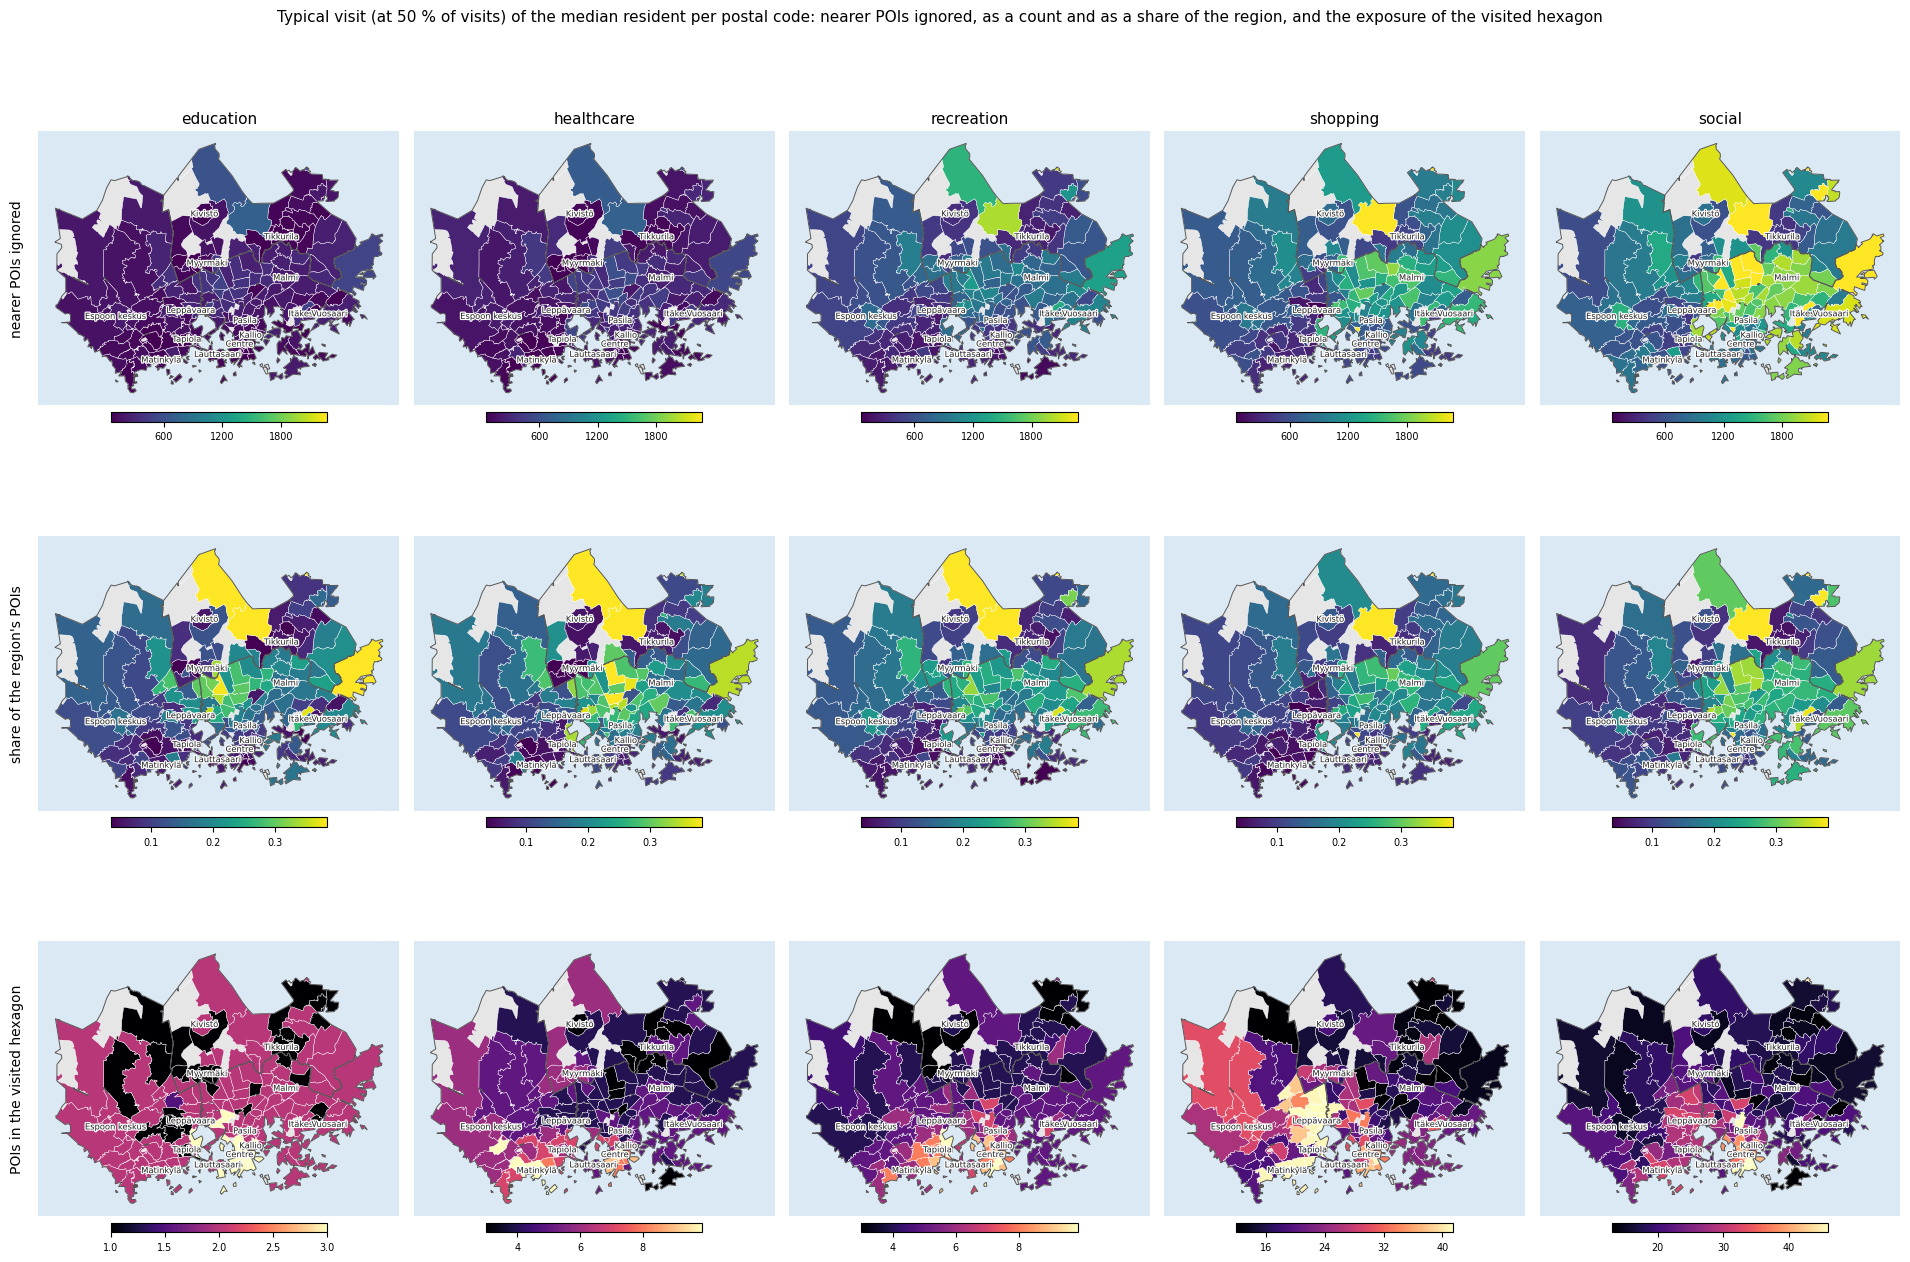

In [12]:
postal_map = postal.loc[~postal["Posnro"].isin(SEA_POSTAL_CODES)].reset_index(drop=True)
water = gpd.read_file(WATER_POLYGONS, bbox=tuple(postal_map.to_crs(3857).total_bounds)).to_crs(postal_map.crs)
postal_map = postal_map.overlay(water[["geometry"]], how="difference")   # postal codes cut to land
municipalities = postal_map.dissolve("Kunta")
landmarks = postal_map.loc[postal_map["Posnro"].isin(LANDMARKS)].copy()
landmarks["label"] = landmarks["Posnro"].map(LANDMARKS)
landmarks["point"] = landmarks.geometry.representative_point()
SEA_COLOUR, HALO = "#dbe9f4", [patheffects.withStroke(linewidth=1.8, foreground="white")]


def draw(axis, values, cmap, vmin, vmax):
    """One choropleth of a series indexed by postal code, on land, with borders and place names."""
    shapes = postal_map.merge(values.rename("value"), left_on="Posnro", right_index=True, how="left")
    postal_map.plot(ax=axis, facecolor="#e6e6e6", edgecolor="white", linewidth=0.3)
    shapes.dropna(subset=["value"]).plot(ax=axis, column="value", cmap=cmap, vmin=vmin, vmax=vmax, edgecolor="white", linewidth=0.3)
    municipalities.boundary.plot(ax=axis, color="#555555", linewidth=0.7)
    for _, place in landmarks.iterrows():
        axis.annotate(place["label"], (place["point"].x, place["point"].y), ha="center", va="center",
                      fontsize=6, color="#222222", path_effects=HALO)
    axis.set_facecolor(SEA_COLOUR)
    axis.set_xticks([])
    axis.set_yticks([])
    for spine in axis.spines.values():
        spine.set_visible(False)


def values_for(column, category):
    rows = by_postal_code.loc[by_postal_code["enough_users"] & (by_postal_code["poi_type"] == category)]
    return rows.set_index("Posnro")[column]


MAP_ROWS = [
    (f"rank_at_{MAIN_THRESHOLD}", "nearer POIs ignored", "viridis", True),
    (f"rank_at_{MAIN_THRESHOLD}_share_of_region", "share of the region's POIs", "viridis", True),
    (f"exposure_at_{MAIN_THRESHOLD}", "POIs in the visited hexagon", "magma", False),
]
figure, axes = plt.subplots(
    nrows=len(MAP_ROWS), ncols=len(CATEGORIES), figsize=(3.8 * len(CATEGORIES) + 0.6, 4.3 * len(MAP_ROWS)),
    gridspec_kw=dict(left=0.04, right=0.99, top=0.9, bottom=0.03, wspace=0.04, hspace=0.3),
)
for row, (column, label, cmap, shared) in zip(axes, MAP_ROWS):
    tables = {c: values_for(column, c) for c in CATEGORIES}
    if shared:
        vmin, vmax = np.nanpercentile(pd.concat(tables.values()), [2, 98])
    for axis, category in zip(row, CATEGORIES):
        if not shared:
            vmin, vmax = np.nanpercentile(tables[category], [2, 98])
        draw(axis, tables[category], cmap, vmin, vmax)
        bar_axis = axis.inset_axes([0.2, -0.06, 0.6, 0.035])
        bar = figure.colorbar(plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin, vmax)), cax=bar_axis, orientation="horizontal")
        bar.ax.tick_params(labelsize=7)
        bar.ax.xaxis.set_major_locator(MaxNLocator(4))
    row[0].text(-0.04, 0.5, label, transform=row[0].transAxes, rotation=90, ha="right", va="center", fontsize=10)
for axis, category in zip(axes[0], CATEGORIES):
    axis.set_title(SHORT[category], fontsize=11)
figure.suptitle(f"Typical visit (at {MAIN_THRESHOLD} % of visits) of the median resident per postal code: nearer POIs ignored, as a count and as a share of the region, and the exposure of the visited hexagon", fontsize=11)
figure.savefig(RESULTS / "map_rank_and_exposure.png", dpi=150, bbox_inches="tight")


One category at full size: the share of the region's POIs ignored on the typical visit
(left) beside the density of that category's POIs in each postal code (right), with
the five postal codes ignoring the most and the fewest named. The scatter below sets
the two against each other across postal codes, with the rank correlation, to see
whether residents of POI-dense parts ignore more or fewer nearer places.

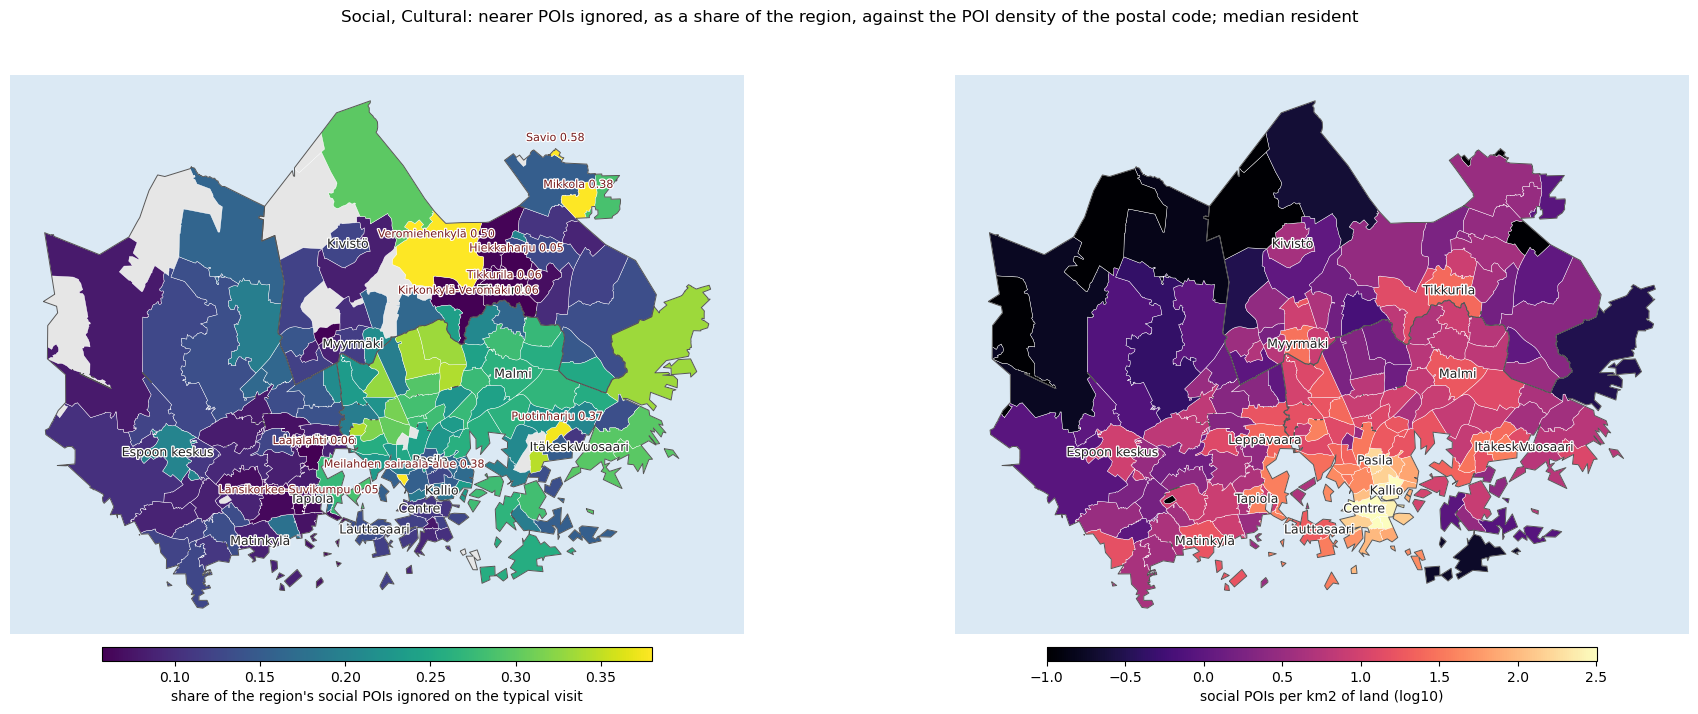

Spearman rank correlation between the share ignored and the POI density across 157 postal codes: 0.07


,share_ignored,pois_per_km2,Nimi,Kunta,end
Posnro,,,,,
04260,0.579,0.000,Savio,Vantaa,most ignored
01530,0.505,2.885,Veromiehenkylä,Vantaa,most ignored
01480,0.384,3.085,Mikkola,Vantaa,most ignored
00290,0.381,31.923,Meilahden sairaala-alue,Helsinki,most ignored
00900,0.375,25.652,Puotinharju,Helsinki,most ignored
02120,0.045,4.600,Länsikorkee-Suvikumpu,Espoo,least ignored
01350,0.052,8.553,Hiekkaharju,Vantaa,least ignored
01510,0.057,13.576,Kirkonkylä-Veromäki,Vantaa,least ignored
01300,0.057,25.293,Tikkurila,Vantaa,least ignored


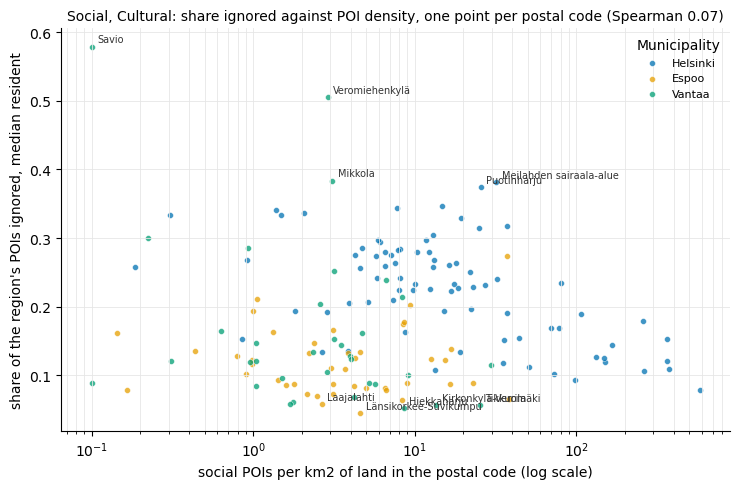

In [13]:
FOCUS_CATEGORY = "Social, Cultural"
N_NAMED = 5

# POIs of each category per postal code (hexagon centres assigned to the postal code) and the land area.
poi_points = gpd.GeoDataFrame(pois.reset_index().rename(columns={"h3_id": "cell"}),
                              geometry=gpd.points_from_xy(poi_xy[:, 0], poi_xy[:, 1]), crs=METRIC_CRS).to_crs(postal_map.crs)
poi_by_postal = gpd.sjoin(poi_points, postal_map[["Posnro", "geometry"]], predicate="within", how="inner").groupby("Posnro")[CATEGORIES].sum()
land_km2 = postal_map.set_index("Posnro").geometry.area / 1e6
density = poi_by_postal.div(land_km2, axis=0).reindex(postal_map["Posnro"]).fillna(0)
density.columns = [f"density_{SHORT[c]}" for c in CATEGORIES]

focus_share = values_for(f"rank_at_{MAIN_THRESHOLD}_share_of_region", FOCUS_CATEGORY)
focus_density = density[f"density_{SHORT[FOCUS_CATEGORY]}"]
names = postal_map.drop_duplicates("Posnro").set_index("Posnro")["Nimi"]
named = pd.concat([focus_share.nlargest(N_NAMED), focus_share.nsmallest(N_NAMED)])

figure, axes = plt.subplots(ncols=2, figsize=(19, 8.2), gridspec_kw=dict(left=0.01, right=0.99, top=0.9, bottom=0.08, wspace=0.03))
panels = [
    (axes[0], focus_share, "viridis", f"share of the region's {SHORT[FOCUS_CATEGORY]} POIs ignored on the typical visit"),
    (axes[1], np.log10(focus_density.clip(lower=0.1)), "magma", f"{SHORT[FOCUS_CATEGORY]} POIs per km2 of land (log10)"),
]
for axis, values, cmap, label in panels:
    vmin, vmax = np.nanpercentile(values, [2, 98])
    draw(axis, values, cmap, vmin, vmax)
    for text in axis.texts:
        text.set_fontsize(9)
    bar = figure.colorbar(plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin, vmax)), ax=axis, orientation="horizontal", shrink=0.6, pad=0.02, aspect=40)
    bar.set_label(label, fontsize=10)
for code_, value in named.items():
    point = postal_map.loc[postal_map["Posnro"] == code_].geometry.representative_point().iloc[0]
    axes[0].annotate(f"{names[code_]} {value:.2f}", (point.x, point.y), xytext=(0, 9), textcoords="offset points",
                     ha="center", fontsize=8, color="#7a1f1f", path_effects=HALO)
figure.suptitle(f"{FOCUS_CATEGORY}: nearer POIs ignored, as a share of the region, against the POI density of the postal code; median resident", fontsize=12)
figure.savefig(RESULTS / f"map_focus_{SHORT[FOCUS_CATEGORY]}.png", dpi=150, bbox_inches="tight")
plt.show()

pairs = pd.DataFrame({"share_ignored": focus_share, "pois_per_km2": focus_density}).dropna()
pairs = pairs.join(postal_map.drop_duplicates("Posnro").set_index("Posnro")[["Nimi", "Kunta"]])
rho = pairs["share_ignored"].corr(pairs["pois_per_km2"], method="spearman")
figure, axis = plt.subplots(figsize=(7.5, 5))
for kunta, colour in KUNTA_COLOURS.items():
    sub = pairs.loc[pairs["Kunta"] == kunta]
    axis.scatter(sub["pois_per_km2"].clip(lower=0.1), sub["share_ignored"], s=18, color=colour, alpha=0.75, edgecolor="white", linewidth=0.4, label=kunta)
for code_, row in pairs.loc[named.index].iterrows():
    axis.annotate(row["Nimi"], (max(row["pois_per_km2"], 0.1), row["share_ignored"]), fontsize=7, xytext=(4, 3), textcoords="offset points", color="#333333")
axis.set_xscale("log")
axis.set_xlabel(f"{SHORT[FOCUS_CATEGORY]} POIs per km2 of land in the postal code (log scale)")
axis.set_ylabel("share of the region's POIs ignored, median resident")
axis.set_title(f"{FOCUS_CATEGORY}: share ignored against POI density, one point per postal code (Spearman {rho:.2f})", fontsize=10)
axis.legend(frameon=False, title="Municipality", fontsize=8)
axis.grid(color="#e6e6e6", linewidth=0.6, which="both")
axis.spines[["top", "right"]].set_visible(False)
figure.tight_layout()
figure.savefig(RESULTS / f"scatter_focus_{SHORT[FOCUS_CATEGORY]}.png", dpi=150)
print(f"Spearman rank correlation between the share ignored and the POI density across {len(pairs)} postal codes: {rho:.2f}")
pd.concat([pairs.loc[named.index[:N_NAMED]].assign(end="most ignored"), pairs.loc[named.index[N_NAMED:]].assign(end="least ignored")]).round(3)

## 7. Rank against exposure

Does the rank grow with the exposure of the places visited, that is do residents who
go to hexagons dense in POIs pass over more nearer places? Each point is a postal
code and category: the typical rank against the exposure of the typical visit,
median resident; the line is a power law fitted across postal codes (slope 1 would
mean the rank is proportional to the exposure, slope 0 independent of it). The
binned table reads the same relation by exposure quintile.

,slope,intercept_log10,r2_log,postal_codes
poi_type,,,,
Education,0.11,2.16,0.00,156
Healthcare and Health,-0.86,2.91,0.13,156
"Recreational, Outdoors",-0.67,3.19,0.11,157
"Shopping, Errands",-0.69,3.83,0.20,157
"Social, Cultural",-0.14,3.26,0.01,157


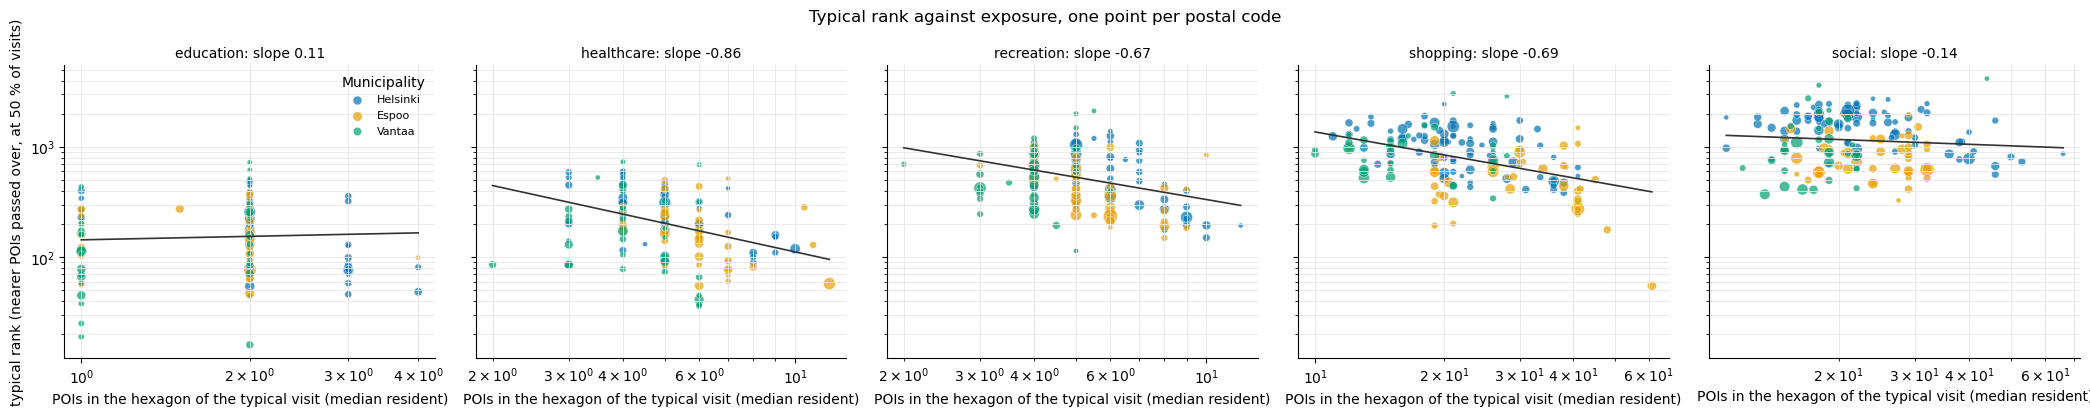

In [14]:
MAIN_RANK = f"rank_at_{MAIN_THRESHOLD}"
EXPOSURE = f"exposure_at_{MAIN_THRESHOLD}"
points = by_postal_code.loc[by_postal_code["enough_users"] & (by_postal_code[EXPOSURE] > 0) & (by_postal_code[MAIN_RANK] > 0)]

fits = []
figure, axes = plt.subplots(ncols=len(CATEGORIES), figsize=(4.2 * len(CATEGORIES), 4.2), sharey=True)
for axis, category in zip(axes, CATEGORIES):
    sub = points.loc[points["poi_type"] == category]
    slope, intercept = np.polyfit(np.log10(sub[EXPOSURE]), np.log10(sub[MAIN_RANK]), 1)
    fitted = 10 ** (intercept + slope * np.log10(sub[EXPOSURE]))
    r2 = 1 - ((np.log10(sub[MAIN_RANK]) - np.log10(fitted)) ** 2).sum() / ((np.log10(sub[MAIN_RANK]) - np.log10(sub[MAIN_RANK]).mean()) ** 2).sum()
    fits.append({"poi_type": category, "slope": slope, "intercept_log10": intercept, "r2_log": r2, "postal_codes": len(sub)})
    for kunta, colour in KUNTA_COLOURS.items():
        k = sub.loc[sub["Kunta"] == kunta]
        axis.scatter(k[EXPOSURE], k[MAIN_RANK], s=10 + k["n_users"] / 10, color=colour, alpha=0.7, edgecolor="white", linewidth=0.4, label=kunta)
    grid = np.logspace(np.log10(sub[EXPOSURE].min()), np.log10(sub[EXPOSURE].max()), 50)
    axis.plot(grid, 10 ** (intercept + slope * np.log10(grid)), color="#333333", linewidth=1.2)
    axis.set_xscale("log")
    axis.set_yscale("log")
    axis.set_title(f"{SHORT[category]}: slope {slope:.2f}", fontsize=10)
    axis.set_xlabel("POIs in the hexagon of the typical visit (median resident)")
    axis.grid(color="#e6e6e6", linewidth=0.6, which="both")
    axis.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel(f"typical rank (nearer POIs passed over, at {MAIN_THRESHOLD} % of visits)")
axes[0].legend(frameon=False, title="Municipality", fontsize=8)
figure.suptitle("Typical rank against exposure, one point per postal code")
figure.tight_layout()
figure.savefig(RESULTS / "scatter_rank_exposure.png", dpi=150)
fits = pd.DataFrame(fits).set_index("poi_type")
fits.round(2)

In [15]:
binned = []
for category in CATEGORIES:
    sub = by_postal_code.loc[by_postal_code["enough_users"] & (by_postal_code["poi_type"] == category)].copy()
    sub["exposure_quintile"] = pd.qcut(sub[EXPOSURE].rank(method="first"), 5, labels=[f"Q{i}" for i in range(1, 6)])
    binned.append(sub.groupby("exposure_quintile", observed=True).agg(
        exposure=(EXPOSURE, "median"), rank=(MAIN_RANK, "median"), share_nearest=("share_nearest", "median"),
        detour_ratio=(f"detour_ratio_at_{MAIN_THRESHOLD}", "median"), postal_codes=("Posnro", "size")).assign(poi_type=SHORT[category]))
binned = pd.concat(binned).reset_index().set_index(["poi_type", "exposure_quintile"])
print("By quintile of the exposure of the typical visit, medians across postal codes:")
binned.round(2)

By quintile of the exposure of the typical visit, medians across postal codes:


exposure     rank  share_nearest  detour_ratio  \
poi_type   exposure_quintile                                                   
education  Q1                     1.00   115.00            0.0         12.22   
           Q2                     2.00   212.00            0.0         11.07   
           Q3                     2.00   224.00            0.0         14.13   
           Q4                     2.00   107.00            0.0         13.11   
           Q5                     3.00   145.00            0.0         10.06   
healthcare Q1                     4.00   325.75            0.0         13.74   
           Q2                     4.00   257.00            0.0         12.66   
           Q3                     5.00   258.00            0.0         11.31   
           Q4                     5.00   182.50            0.0          8.26   
           Q5                     7.00   125.00            0.0          8.39   
recreation Q1                     4.00   621.50            0.0         20.25   
           Q2                     4.50   691.00            0.0         19.98   
           Q3                     5.00   676.00            0.0         21.60   
           Q4                     6.00   509.50            0.0         16.78   
           Q5                     8.00   315.75            0.0         12.07   
shopping   Q1                    13.00   984.50            0.0         17.66   
           Q2                    19.00  1141.00            0.0         17.84   
           Q3                    21.00   907.00            0.0         15.39   
           Q4                    26.00   755.50            0.0         16.65   
           Q5                    38.25   482.75            0.0          9.61   
social     Q1                    15.00  1171.50            0.0         21.77   
           Q2                    18.00  1469.00            0.0         22.62   
           Q3                    21.00  1481.50            0.0         20.98   
           Q4                    26.00  1215.50            0.0         19.60   
           Q5                    32.00   903.00            0.0         14.78   

                              postal_codes  
poi_type   exposure_quintile                
education  Q1                           32  
           Q2                           31  
           Q3                           31  
           Q4                           31  
           Q5                           31  
healthcare Q1                           32  
           Q2                           31  
           Q3                           31  
           Q4                           31  
           Q5                           31  
recreation Q1                           32  
           Q2                           31  
           Q3                           31  
           Q4                           31  
           Q5                           32  
shopping   Q1                           32  
           Q2                           31  
           Q3                           31  
           Q4                           31  
           Q5                           32  
social     Q1                           32  
           Q2                           31  
           Q3                           31  
           Q4                           31  
           Q5                           32

## 8. Is there one share for every category?

The share of the region's POIs ignored, per resident and category, at the near (20 %)
and the typical (50 %) threshold: percentiles across residents, then across the
postal-code medians, and box plots (box: quartiles, whiskers: 5th to 95th percentile,
line: median; the dashed line is the median pooled over the five categories). If the
boxes overlap and the medians sit close to the pooled line, one share can stand for
every category in another city.

Share of the region's POIs ignored, percentiles across residents:


p5    p10    p25    p50    p75  \
at 20 % of visits Education               0.000  0.001  0.005  0.029  0.145   
                  Healthcare and Health   0.001  0.002  0.009  0.034  0.148   
                  Recreational, Outdoors  0.001  0.002  0.007  0.032  0.134   
                  Shopping, Errands       0.001  0.002  0.008  0.037  0.136   
                  Social, Cultural        0.001  0.002  0.008  0.038  0.194   
                  all categories pooled   0.001  0.002  0.007  0.034  0.150   
at 50 % of visits Education               0.002  0.004  0.019  0.110  0.365   
                  Healthcare and Health   0.003  0.008  0.030  0.131  0.387   
                  Recreational, Outdoors  0.003  0.008  0.033  0.128  0.363   
                  Shopping, Errands       0.003  0.008  0.035  0.123  0.342   
                  Social, Cultural        0.003  0.007  0.032  0.160  0.413   
                  all categories pooled   0.003  0.007  0.030  0.129  0.375   

                                            p90    p95  
at 20 % of visits Education               0.387  0.518  
                  Healthcare and Health   0.390  0.526  
                  Recreational, Outdoors  0.360  0.480  
                  Shopping, Errands       0.351  0.493  
                  Social, Cultural        0.422  0.545  
                  all categories pooled   0.383  0.514  
at 50 % of visits Education               0.561  0.646  
                  Healthcare and Health   0.588  0.664  
                  Recreational, Outdoors  0.544  0.626  
                  Shopping, Errands       0.553  0.655  
                  Social, Cultural        0.594  0.685  
                  all categories pooled   0.567  0.656

The same across postal codes (median resident of each postal code):


p5    p10    p25    p50    p75  \
                  poi_type                                                    
at 20 % of visits Education               0.009  0.013  0.019  0.031  0.055   
                  Healthcare and Health   0.009  0.012  0.022  0.037  0.063   
                  Recreational, Outdoors  0.011  0.015  0.022  0.037  0.056   
                  Shopping, Errands       0.010  0.014  0.026  0.042  0.056   
                  Social, Cultural        0.011  0.013  0.025  0.041  0.066   
at 50 % of visits Education               0.037  0.051  0.076  0.126  0.192   
                  Healthcare and Health   0.042  0.054  0.086  0.146  0.221   
                  Recreational, Outdoors  0.051  0.061  0.091  0.153  0.222   
                  Shopping, Errands       0.049  0.063  0.085  0.133  0.187   
                  Social, Cultural        0.065  0.080  0.109  0.162  0.251   

                                            p90    p95  
                  poi_type                              
at 20 % of visits Education               0.100  0.138  
                  Healthcare and Health   0.091  0.121  
                  Recreational, Outdoors  0.084  0.102  
                  Shopping, Errands       0.077  0.095  
                  Social, Cultural        0.097  0.126  
at 50 % of visits Education               0.280  0.339  
                  Healthcare and Health   0.294  0.346  
                  Recreational, Outdoors  0.262  0.297  
                  Shopping, Errands       0.244  0.264  
                  Social, Cultural        0.298  0.338

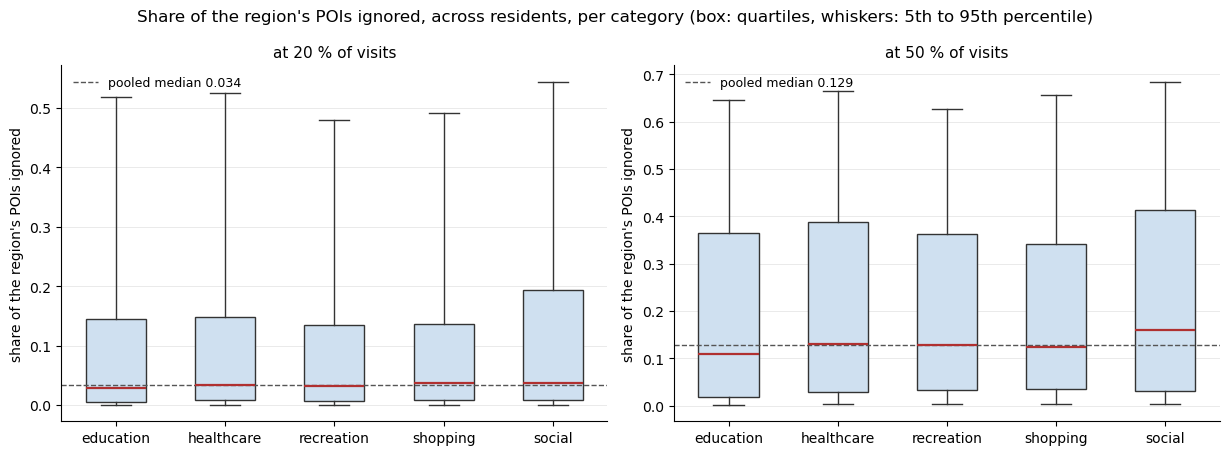

In [16]:
SHARE_COLUMNS = {t: f"rank_at_{t}_share_of_region" for t in THRESHOLDS}
PERCENTILES = [0.05, 0.1, 0.25, 0.5, 0.75, 0.9, 0.95]

across_users = pd.concat(
    {f"at {t} % of visits": by_user.groupby("poi_type")[SHARE_COLUMNS[t]].quantile(PERCENTILES).unstack() for t in THRESHOLDS}
)
across_users.columns = [f"p{int(p * 100)}" for p in PERCENTILES]
pooled_users = pd.concat({f"at {t} % of visits": by_user[SHARE_COLUMNS[t]].quantile(PERCENTILES) for t in THRESHOLDS}, axis=1).T
pooled_users.columns = across_users.columns
pooled_users.index = pd.MultiIndex.from_tuples([(k, "all categories pooled") for k in pooled_users.index])
across_users = pd.concat([across_users, pooled_users]).sort_index(level=0, sort_remaining=False)
print("Share of the region's POIs ignored, percentiles across residents:")
display(across_users.round(3))

postal_enough = by_postal_code.loc[by_postal_code["enough_users"]]
across_postal = pd.concat(
    {f"at {t} % of visits": postal_enough.groupby("poi_type")[SHARE_COLUMNS[t]].quantile(PERCENTILES).unstack() for t in THRESHOLDS}
)
across_postal.columns = across_users.columns
print("The same across postal codes (median resident of each postal code):")
display(across_postal.round(3))

figure, axes = plt.subplots(ncols=len(THRESHOLDS), figsize=(6.2 * len(THRESHOLDS), 4.6), sharey=False)
for axis, t in zip(axes, THRESHOLDS):
    data = [by_user.loc[by_user["poi_type"] == c, SHARE_COLUMNS[t]].dropna() for c in CATEGORIES]
    axis.boxplot(data, whis=(5, 95), showfliers=False, widths=0.55, patch_artist=True,
                 boxprops=dict(facecolor="#cfe0f0", edgecolor="#333333"), medianprops=dict(color="#b03030", linewidth=1.6),
                 whiskerprops=dict(color="#333333"), capprops=dict(color="#333333"))
    axis.axhline(by_user[SHARE_COLUMNS[t]].median(), color="#555555", linestyle="--", linewidth=1,
                 label=f"pooled median {by_user[SHARE_COLUMNS[t]].median():.3f}")
    axis.set_xticks(range(1, len(CATEGORIES) + 1))
    axis.set_xticklabels([SHORT[c] for c in CATEGORIES])
    axis.set_ylabel("share of the region's POIs ignored")
    axis.set_title(f"at {t} % of visits", fontsize=11)
    axis.legend(frameon=False, fontsize=9, loc="upper left")
    axis.grid(axis="y", color="#e6e6e6", linewidth=0.6)
    axis.spines[["top", "right"]].set_visible(False)
figure.suptitle("Share of the region's POIs ignored, across residents, per category (box: quartiles, whiskers: 5th to 95th percentile)")
figure.tight_layout()
figure.savefig(RESULTS / "box_share_ignored.png", dpi=150)

## 9. The numbers to carry over

Per category: the typical rank city-wide, as a count and as a share of the region's
POIs of the category, its spread across residents and across postal codes, the rank
at the near threshold, the share of visits to a nearest POI, and the exposure slope.

Two ways to use them in a city without stays. As a count: the typical trip for a
category is the trip to the (rank + 1)-th nearest POI of that category by walking
distance on that city's street network from each hexagon, routed afterwards by each
mode, which keeps the same definition of "nearer" as the calibration. As a share: the typical visit
reaches past that share of the region's POIs, which is the access level of `02.4`
read from behaviour rather than set by hand. The exposure slope says whether the
count depends on how dense in POIs the places visited are.

In [17]:
by_postal_enough = by_postal_code.loc[by_postal_code["enough_users"]]
carry = city.join(
    by_postal_enough.groupby("poi_type")[MAIN_RANK].agg(rank_postal_p25=lambda s: s.quantile(0.25), rank_postal_median="median", rank_postal_p75=lambda s: s.quantile(0.75))
).join(
    by_postal_enough.groupby("poi_type")[f"{MAIN_RANK}_share_of_region"].agg(share_postal_p25=lambda s: s.quantile(0.25), share_postal_median="median", share_postal_p75=lambda s: s.quantile(0.75))
).join(fits[["slope", "r2_log"]].rename(columns={"slope": "exposure_slope", "r2_log": "exposure_fit_r2"}))
carry.round(3).to_csv(RESULTS / "rank_summary.csv")
print("Rank = nearer POIs of the same category passed over on the typical visit; (rank + 1) is the nearest-neighbour order to route to.")
carry.round(3).T

Rank = nearer POIs of the same category passed over on the typical visit; (rank + 1) is the nearest-neighbour order to route to.


poi_type,Education,Healthcare and Health,"Recreational, Outdoors","Shopping, Errands","Social, Cultural"
users,28861.000,27706.000,39643.000,37138.000,40431.000
region_pois,1289.000,1523.000,3809.000,6280.000,7206.000
rank_at_20_median,37.000,52.000,122.000,233.500,272.000
rank_at_50_median,142.000,200.000,486.000,775.000,1150.000
rank_at_20_share_of_region,0.029,0.034,0.032,0.037,0.038
rank_at_50_share_of_region,0.110,0.131,0.128,0.123,0.160
rank_at_50_p25,25.000,46.000,126.000,221.000,231.000
rank_at_50_p75,471.000,590.000,1382.000,2150.750,2976.500
share_nearest_mean,0.032,0.024,0.010,0.010,0.007
distance_km_at_50_median,5.474,6.142,6.314,6.157,6.968


## Caveats

- Ranks use walking distance along the street network between hexagon centres, so
  water, rail and motorways are honoured; the straight-line ranks are kept for
  comparison. The walking network is mode-neutral but not the road a car takes.
- A visited hexagon that holds several POIs of the category counts once per POI, so
  dense hexagons weigh more, as in the paper's curves; which POI inside the hexagon
  was visited is unknown, and all POIs in it share the same rank.
- POIs in the home hexagon always count as nearer, so a resident of a dense centre
  hexagon starts with a rank equal to the POIs in their own hexagon, and their nearest
  POI is at distance zero, floored at `HEXAGON_RADIUS_M` for the detour ratio.
- A share of the region's POIs depends on where the region boundary is drawn; here
  it is the three municipalities of the postal-code layer.
- The categories are the paper's five; another city needs the same category
  definitions on its POI data for the rank to mean the same thing.